# Chapitre 5 - Exercices 5.1 à 5.5

Base des puissances tronquées, propriétés des B-splines, variance ponctuelle (figure 5.3),
contraintes des splines naturelles et filtrage des phonèmes pour une analyse
discriminante quadratique.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch05_splines import (truncated_power_basis, bspline_basis, augmented_knots,
                              natural_spline_basis)
set_style()

## Exercice 5.1 : La base des puissances tronquées

**Énoncé.** Montrer que les fonctions de l'éq. (5.3),
$h_1 = 1$, $h_2 = X$, $h_3 = X^2$, $h_4 = X^3$, $h_5 = (X - \xi_1)_+^3$,
$h_6 = (X - \xi_2)_+^3$, forment une base de l'espace des splines cubiques de nœuds
$\xi_1 < \xi_2$.

**Rappel.** Une spline cubique de nœuds $\xi_1 < \xi_2$ est une fonction $f : \mathbb R
\to \mathbb R$ qui est un polynôme de degré $\le 3$ sur chacun des intervalles
$(-\infty, \xi_1]$, $[\xi_1, \xi_2]$, $[\xi_2, +\infty)$, et de classe $C^2$ (continue,
ainsi que $f'$ et $f''$). L'ensemble $\mathcal S$ de ces fonctions est un espace vectoriel
(stable par combinaison linéaire). Il faut montrer trois choses : les $h_m$ sont dans
$\mathcal S$, elles sont libres, et elles engendrent $\mathcal S$.

**1. Les $h_m$ sont des splines cubiques.** C'est clair pour $1, X, X^2, X^3$. Pour
$g(X) = (X - \xi)_+^3$ : $g$ vaut $0$ sur $(-\infty, \xi]$ et $(X - \xi)^3$ sur
$[\xi, +\infty)$, deux polynômes de degré $\le 3$. Ses dérivées à gauche de $\xi$ sont
nulles, à droite elles valent $3(X-\xi)^2$, $6(X - \xi)$, qui tendent vers $0$ en $\xi$.
Donc $g, g', g''$ sont continues en $\xi$ : $g \in C^2$. (La dérivée troisième saute de
$0$ à $6$.)

**2. Liberté.** Supposons $\sum_{j=0}^{3}\beta_jX^j + \theta_1(X-\xi_1)_+^3 +
\theta_2(X-\xi_2)_+^3 = 0$ pour tout $X$.

- Sur $(-\infty, \xi_1)$, les deux puissances tronquées sont nulles : le polynôme
  $\sum\beta_jX^j$ s'annule sur un intervalle, donc tous ses coefficients sont nuls.
- Sur $(\xi_1, \xi_2)$, il reste $\theta_1(X - \xi_1)^3 = 0$, donc $\theta_1 = 0$.
- Sur $(\xi_2, +\infty)$, il reste $\theta_2(X - \xi_2)^3 = 0$, donc $\theta_2 = 0$.

**3. Les $h_m$ engendrent $\mathcal S$.** Soit $f \in \mathcal S$ et $p_0$ le polynôme
égal à $f$ sur $(-\infty, \xi_1]$ ; posons $g = f - p_0 \in \mathcal S$, nulle sur
$(-\infty, \xi_1]$.

- Sur $[\xi_1, \xi_2]$, $g$ est un polynôme $q$ de degré $\le 3$ et, par continuité de
  $g, g', g''$ en $\xi_1$, $q(\xi_1) = q'(\xi_1) = q''(\xi_1) = 0$. La formule de Taylor
  (exacte pour un polynôme de degré 3) donne $q(X) = \frac{q'''(\xi_1)}{6}(X-\xi_1)^3 =
  c_1(X - \xi_1)^3$.
- La fonction $g_1 = g - c_1(X - \xi_1)_+^3$ est dans $\mathcal S$ et nulle sur
  $(-\infty, \xi_2]$. Le même argument en $\xi_2$ donne $g_1 = c_2(X - \xi_2)_+^3$.

Ainsi $f = p_0 + c_1(X - \xi_1)_+^3 + c_2(X - \xi_2)_+^3$ : $\dim\mathcal S = 6$. Le même
raisonnement montre qu'une spline d'ordre $M$ à $K$ nœuds s'écrit dans la base
$\{X^{j}\}_{j<M} \cup \{(X - \xi_k)_+^{M-1}\}_{k \le K}$, de dimension $M + K$.

**Vérification numérique.** Construisons une spline cubique « au hasard » par une autre
voie (combinaison aléatoire de B-splines, cf. cours 1) et vérifions qu'elle s'écrit
**exactement** dans la base (5.3).

In [2]:
rng = np.random.RandomState(0)
xi = np.array([0.3, 0.7])
x = np.linspace(0, 1, 500)
f_rand = bspline_basis(x, xi, 0, 1) @ rng.randn(6)
H = truncated_power_basis(x, xi)
coef, *_ = np.linalg.lstsq(H, f_rand, rcond=None)
print("rang de H :", np.linalg.matrix_rank(H), "| résidu max :", np.abs(H @ coef - f_rand).max())

rang de H : 6 | résidu max : 2.0372592501871623e-14


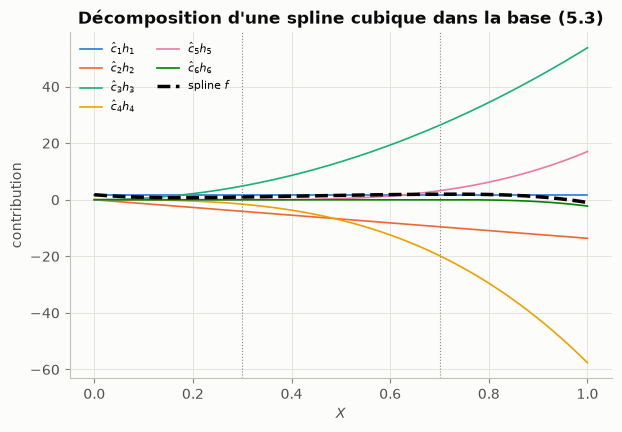

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for j in range(6):
    ax.plot(x, coef[j] * H[:, j], lw=1.2, color=COLORS[j], label="$\\hat c_{%d} h_{%d}$" % (j + 1, j + 1))
ax.plot(x, f_rand, color="k", lw=2.5, ls="--", label="spline $f$")
for k in xi:
    ax.axvline(k, color=GRAY, lw=0.8, ls=":")
ax.set_xlabel("$X$")
ax.set_ylabel("contribution")
ax.set_title("Décomposition d'une spline cubique dans la base (5.3)")
ax.legend(ncol=2, fontsize=8)
plt.show()

> **À retenir.** Les puissances tronquées encodent directement le saut de la dérivée
> d'ordre $M - 1$ en chaque nœud ; la preuve « on retire le polynôme de gauche, puis on
> avance de nœud en nœud » montre que la dimension vaut $M + K$.

## Exercice 5.2 : Propriétés des B-splines

**Énoncé.** Soit $B_{i,M}$ la B-spline d'ordre $M$ définie par la récurrence
(5.77)-(5.78) (rappelée ci-dessous) sur la suite de nœuds augmentée $\tau$. Montrer par
récurrence :

(a) $B_{i,M}(x) = 0$ pour $x \notin [\tau_i, \tau_{i+M}]$ (support d'au plus $M+1$ nœuds) ;
(b) $B_{i,M}(x) > 0$ pour $x \in (\tau_i, \tau_{i+M})$ ;
(c) $\sum_{i=1}^{K+M}B_{i,M}(x) = 1$ pour $x \in [\xi_0, \xi_{K+1}]$ ;
(d) $B_{i,M}$ est polynomiale par morceaux de degré $M - 1$ sur $[\xi_0, \xi_{K+1}]$,
    avec des cassures seulement aux nœuds ;
(e) une B-spline d'ordre $M$ est la densité d'une somme (convolution) de $M$ variables
    uniformes.

**Rappels.** $B_{i,1}(x) = \mathbf 1(\tau_i \le x < \tau_{i+1})$, et pour $m \ge 2$

$$
B_{i,m}(x) = \underbrace{\frac{x - \tau_i}{\tau_{i+m-1} - \tau_i}}_{w_{i,m}(x)}B_{i,m-1}(x)
 + \underbrace{\frac{\tau_{i+m} - x}{\tau_{i+m} - \tau_{i+1}}}_{\bar w_{i,m}(x)}B_{i+1,m-1}(x),
$$

avec la convention qu'un terme dont le dénominateur est nul est nul (dans ce cas, la
B-spline qu'il multiplie est identiquement nulle, comme on le verra en (a)).

**(a) Support.** Pour $m = 1$, $B_{i,1}$ est nulle hors de $[\tau_i, \tau_{i+1})$.
Supposons la propriété vraie à l'ordre $m - 1$ : $B_{i,m-1}$ est nulle hors de
$[\tau_i, \tau_{i+m-1}]$ et $B_{i+1,m-1}$ hors de $[\tau_{i+1}, \tau_{i+m}]$. Ces deux
intervalles sont inclus dans $[\tau_i, \tau_{i+m}]$, donc hors de cet intervalle les deux
termes de la récurrence sont nuls : $B_{i,m}(x) = 0$. Pour $M = 4$, le support
$[\tau_i, \tau_{i+4}]$ fait intervenir 5 nœuds.

En particulier, si $\tau_i = \tau_{i+m}$, $B_{i,m} \equiv 0$ (sauf sur un point), ce qui
justifie la convention $0/0 = 0$.

**(b) Positivité.** Montrons d'abord $B_{i,m} \ge 0$ partout. Vrai pour $m = 1$. Si c'est
vrai à l'ordre $m - 1$ : là où $B_{i,m-1}(x) \ne 0$ on a $x \ge \tau_i$ par (a), donc
$w_{i,m}(x) \ge 0$ ; là où $B_{i+1,m-1}(x) \ne 0$ on a $x \le \tau_{i+m}$, donc
$\bar w_{i,m}(x) \ge 0$. Les deux termes sont $\ge 0$.

Stricte positivité, pour des nœuds distincts (cas simple) : par récurrence, $B_{i,m-1} > 0$
sur $(\tau_i, \tau_{i+m-1})$ et $B_{i+1,m-1} > 0$ sur $(\tau_{i+1}, \tau_{i+m})$. Soit
$x \in (\tau_i, \tau_{i+m})$ :

- si $x < \tau_{i+m-1}$ : $w_{i,m}(x) > 0$ (car $x > \tau_i$) et $B_{i,m-1}(x) > 0$, le
  premier terme est $> 0$ ;
- si $x > \tau_{i+1}$ : de même le second terme est $> 0$.

Pour $m \ge 3$, $\tau_{i+1} < \tau_{i+m-1}$ et l'un des deux cas a toujours lieu. Pour
$m = 2$, le seul point non couvert est $x = \tau_{i+1}$, où un calcul direct donne
$B_{i,2}(\tau_{i+1}) = \bar w_{i,2}(\tau_{i+1})B_{i+1,1}(\tau_{i+1}) = 1 > 0$. Avec des
nœuds répétés, le même argument s'applique sur les intervalles non dégénérés.

**(c) Partition de l'unité.** Notons $n_m = K + 2M - m$ le nombre de B-splines d'ordre $m$.
En sommant la récurrence et en posant $j = i + 1$ dans le second terme :

$$
\sum_{i=1}^{n_m}B_{i,m}(x) = \sum_{i=1}^{n_m}w_{i,m}(x)B_{i,m-1}(x)
  + \sum_{j=2}^{n_m+1}\bar w_{j-1,m}(x)B_{j,m-1}(x).
$$

Or $w_{j,m}(x) + \bar w_{j-1,m}(x) = \frac{x - \tau_j}{\tau_{j+m-1} - \tau_j} +
\frac{\tau_{j+m-1} - x}{\tau_{j+m-1} - \tau_j} = 1$ (les deux fractions ont le même
dénominateur). Les deux termes « orphelins » sont $B_{1,m-1}$ (support
$[\tau_1, \tau_m] = \{\xi_0\}$ quand $m \le M$) et $B_{n_{m-1},m-1}$ (support réduit à
$\{\xi_{K+1}\}$) : ils sont nuls sur l'intervalle. Donc
$\sum_iB_{i,m} = \sum_jB_{j,m-1}$ sur $[\xi_0, \xi_{K+1}]$, et par récurrence
$= \sum_iB_{i,1} = 1$, car chaque $x$ appartient à exactement un intervalle
$[\tau_i, \tau_{i+1})$ (le point $\xi_{K+1}$ étant rattaché au dernier intervalle).

**(d) Polynômes par morceaux.** $B_{i,1}$ est constante sur chaque intervalle entre
nœuds consécutifs. Si $B_{i,m-1}$ et $B_{i+1,m-1}$ sont polynomiales de degré $\le m-2$
sur chacun de ces intervalles, alors $B_{i,m}$, combinaison à coefficients **affines**
$w, \bar w$, est polynomiale de degré $\le m - 1$ sur ces mêmes intervalles. Les seuls
points de cassure possibles sont donc les nœuds. (On montre de plus que $B_{i,M}$ est
de classe $C^{M-2}$ en un nœud simple : c'est une spline.)

**(e) Convolution d'uniformes.** Prenons des nœuds **équidistants** de pas 1,
$\tau_i = i$. Par invariance par translation, $B_{i,m}(x) = N_m(x - i)$ où
$N_m = B_{0,m}$ a pour support $[0, m]$, et la récurrence devient

$$
N_m(x) = \frac{x}{m-1}N_{m-1}(x) + \frac{m - x}{m-1}N_{m-1}(x - 1). \tag{R}
$$

**Lemme.** Pour $m \ge 2$ et $x$ hors des nœuds : $N_m'(x) = N_{m-1}(x) - N_{m-1}(x-1)$.

*Preuve par récurrence.* Pour $m = 2$, $N_2$ est la fonction « chapeau » ($x$ sur
$[0, 1]$, $2 - x$ sur $[1, 2]$), de dérivée $1$ puis $-1$ : c'est
$N_1(x) - N_1(x-1)$. Supposons le lemme vrai à l'ordre $m - 1 \ge 2$ et dérivons (R) :

$$
N_m'(x) = \frac{N_{m-1}(x) - N_{m-1}(x-1)}{m-1}
  + \frac{x\,N_{m-1}'(x) + (m-x)\,N_{m-1}'(x-1)}{m-1}.
$$

Par l'hypothèse de récurrence, le numérateur du second terme vaut
$A := xN_{m-2}(x) + (m - 2x)N_{m-2}(x-1) - (m-x)N_{m-2}(x-2)$. Par ailleurs, en écrivant
(R) à l'ordre $m-1$ en $x$ et en $x - 1$ :

$$
(m-2)\big[N_{m-1}(x) - N_{m-1}(x-1)\big] = xN_{m-2}(x) + (m-1-x)N_{m-2}(x-1)
 - (x-1)N_{m-2}(x-1) - (m-x)N_{m-2}(x-2) = A.
$$

Donc $N_m'(x) = \frac{1 + (m-2)}{m-1}\big[N_{m-1}(x) - N_{m-1}(x-1)\big]$, ce qui prouve
le lemme.

*Conclusion.* Soient $U_1, U_2, \dots$ i.i.d. de loi $\mathcal U[0, 1]$ et $g_m$ la
densité de $S_m = U_1 + \dots + U_m$. On a $g_1 = \mathbf 1_{[0,1)} = N_1$ et, par la
formule de convolution,
$g_m(x) = \int_0^1 g_{m-1}(x - u)\,du = \int_{x-1}^{x}g_{m-1}(s)\,ds$, d'où
$g_m'(x) = g_{m-1}(x) - g_{m-1}(x-1)$. Si $g_{m-1} = N_{m-1}$, alors $g_m$ et $N_m$ ont
la même dérivée (sauf en un nombre fini de points), sont continues (pour $m \ge 2$) et
nulles en $x = 0$ : elles sont égales. Donc $N_M$ **est la densité de la somme de $M$
uniformes**. Pour un pas $h$ quelconque, $B_{i,M}(x)/h$ est la densité de
$\tau_i + h(U_1 + \dots + U_M)$.

**Vérifications numériques** : support, positivité, partition de l'unité (avec des nœuds
irréguliers), puis comparaison de $N_4$ à l'histogramme de $U_1 + \dots + U_4$.

In [4]:
rng = np.random.RandomState(0)
kn = np.sort(rng.uniform(0, 1, 6))
tau = augmented_knots(kn, 0.0, 1.0, 4)
xx = np.linspace(0, 1, 2001)
B = bspline_basis(xx, kn, 0.0, 1.0, order=4)
hors_support = max(np.abs(B[(xx < tau[i]) | (xx > tau[i + 4]), i]).max(initial=0)
                   for i in range(B.shape[1]))
interieur = min(B[(xx > tau[i]) & (xx < tau[i + 4]), i].min() for i in range(B.shape[1]))
print("max hors support         :", hors_support)
print("min à l'intérieur        :", interieur)
print("max |somme - 1|          :", np.abs(B.sum(1) - 1).max())

max hors support         : 0.0
min à l'intérieur        : 4.8783270531962695e-11
max |somme - 1|          : 4.440892098500626e-16


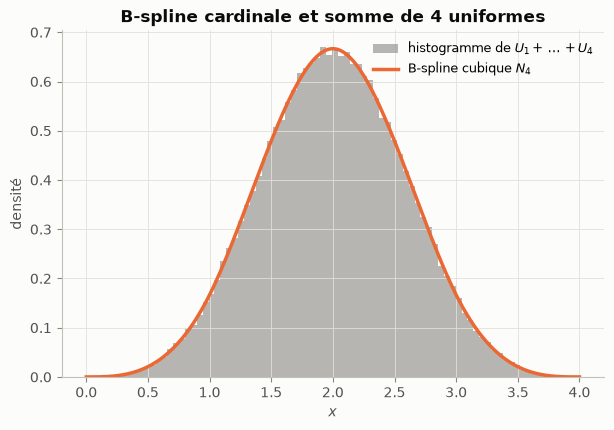

In [5]:
tau_u = np.arange(0, 5.0)                   # nœuds 0,1,2,3,4 : une B-spline cubique cardinale
xs = np.linspace(0, 4, 400)
N4 = bspline_basis(xs, tau_u[1:-1], 0.0, 4.0, order=4)[:, 3]  # B-spline à support [0, 4]
somme = rng.uniform(size=(200000, 4)).sum(1)
plt.figure(figsize=(7, 4.5))
plt.hist(somme, bins=80, density=True, color=GRAY, alpha=0.6, label="histogramme de $U_1+\\dots+U_4$")
plt.plot(xs, N4, color=ORANGE, lw=2.5, label="B-spline cubique $N_4$")
plt.xlabel("$x$")
plt.ylabel("densité")
plt.title("B-spline cardinale et somme de 4 uniformes")
plt.legend()
plt.show()

> **À retenir.** Support local de $M + 1$ nœuds, positivité, partition de l'unité et
> structure polynomiale par morceaux se démontrent tous par récurrence sur l'ordre via la
> formule de Cox-de Boor. À nœuds équidistants, la B-spline est la densité d'une somme
> d'uniformes (d'où son allure « en cloche », cf. théorème central limite).

## Exercice 5.3 : Reproduire la figure 5.3

**Énoncé.** Écrire un programme reproduisant la figure 5.3 : variances ponctuelles de
quatre modèles (droite, cubique globale, spline cubique à 2 nœuds, spline naturelle à 6
nœuds) ajustés par moindres carrés à $N = 50$ points $X \sim \mathcal U[0, 1]$, avec un
bruit de variance constante.

**Rappel.** Pour une base $h = (h_1, \dots, h_M)$ et la matrice $\mathbf H$ des
évaluations aux $x_i$, $\hat f(x_0) = h(x_0)^T(\mathbf H^T\mathbf H)^{-1}\mathbf H^T\mathbf y$
est une forme linéaire en $\mathbf y$ : $\hat f(x_0) = \ell(x_0)^T\mathbf y$. Avec
$\mathrm{Var}(\mathbf y) = \sigma^2\mathbf I$,
$\mathrm{Var}\hat f(x_0) = \sigma^2\|\ell(x_0)\|^2 = \sigma^2h(x_0)^T
(\mathbf H^T\mathbf H)^{-1}h(x_0)$. La variance ne dépend **ni de $f$ ni de $\mathbf y$**,
seulement des $x_i$ et de la base. On prend $\sigma^2 = 1$.

In [6]:
rng = np.random.RandomState(0)
N = 50
x50 = np.sort(rng.uniform(0, 1, N))
modeles = {
    "Linéaire globale": lambda t: np.column_stack([np.ones_like(t), t]),
    "Polynôme cubique global": lambda t: np.vander(t, 4, increasing=True),
    "Spline cubique - 2 nœuds": lambda t: truncated_power_basis(t, [0.33, 0.66]),
    "Spline naturelle - 6 nœuds": lambda t: natural_spline_basis(t, np.linspace(0.1, 0.9, 6)),
}

def var_ponctuelle(Hf, xtr, x0):
    H = Hf(xtr)
    h0 = Hf(x0)
    return np.sum(h0 * np.linalg.solve(H.T @ H, h0.T).T, axis=1)

Validons la formule par Monte-Carlo : on simule 4000 vecteurs $\mathbf y = f(\mathbf x) +
\varepsilon$ (avec $f$ quelconque, ici $\sin(2\pi x)$, et $\varepsilon \sim \mathcal N(0,
\mathbf I)$), on ajuste chaque modèle et on calcule la variance empirique de $\hat f(x_i)$.

In [7]:
Y = np.sin(2 * np.pi * x50)[:, None] + rng.randn(N, 4000)
for nom, Hf in modeles.items():
    H = Hf(x50)
    F = H @ np.linalg.lstsq(H, Y, rcond=None)[0]
    ecart = np.abs(F.var(axis=1) - var_ponctuelle(Hf, x50, x50)).max()
    print("%-28s écart max (Monte-Carlo vs formule) = %.4f" % (nom, ecart))

Linéaire globale             écart max (Monte-Carlo vs formule) = 0.0008
Polynôme cubique global      écart max (Monte-Carlo vs formule) = 0.0066
Spline cubique - 2 nœuds     écart max (Monte-Carlo vs formule) = 0.0046
Spline naturelle - 6 nœuds   écart max (Monte-Carlo vs formule) = 0.0061


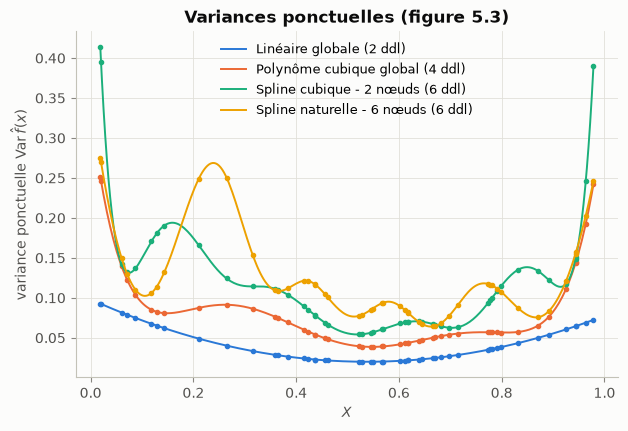

In [8]:
plt.figure(figsize=(7, 4.5))
grille = np.linspace(x50.min(), x50.max(), 300)
for c, (nom, Hf) in zip(COLORS, modeles.items()):
    plt.plot(grille, var_ponctuelle(Hf, x50, grille), color=c, lw=1.4,
             label="%s (%d ddl)" % (nom, Hf(x50).shape[1]))
    plt.plot(x50, var_ponctuelle(Hf, x50, x50), "o", color=c, ms=3)
plt.xlabel("$X$")
plt.ylabel(r"variance ponctuelle $\mathrm{Var}\,\hat f(x)$")
plt.title("Variances ponctuelles (figure 5.3)")
plt.legend()
plt.show()

> **À retenir.** La variance ponctuelle d'un ajustement par moindres carrés,
> $\sigma^2h(x)^T(\mathbf H^T\mathbf H)^{-1}h(x)$, se calcule sans simuler. Elle croît
> fortement aux bords pour les splines cubiques ; la contrainte de linéarité des splines
> naturelles la maîtrise.

## Exercice 5.4 : Contraintes des splines cubiques naturelles

**Énoncé.** On écrit une spline cubique à $K$ nœuds sous la forme (éq. (5.70))

$$
f(X) = \sum_{j=0}^{3}\beta_jX^j + \sum_{k=1}^{K}\theta_k(X - \xi_k)_+^3 .
$$

Montrer que les conditions de bord des splines naturelles (linéarité hors de
$[\xi_1, \xi_K]$) équivalent à (éq. (5.71))
$\beta_2 = \beta_3 = 0$, $\sum_k\theta_k = 0$, $\sum_k\xi_k\theta_k = 0$, et en déduire la
base (5.4)-(5.5).

**À gauche de $\xi_1$.** Pour $X < \xi_1$, toutes les puissances tronquées sont nulles et
$f(X) = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3$. $f$ est affine sur
$(-\infty, \xi_1)$ ssi $f''(X) = 2\beta_2 + 6\beta_3X = 0$ pour tout $X < \xi_1$, i.e.
(un polynôme nul sur un intervalle est nul) $\beta_2 = \beta_3 = 0$.

**À droite de $\xi_K$.** Pour $X > \xi_K$, toutes les puissances tronquées sont
« actives » ; en développant $(X - \xi_k)^3 = X^3 - 3\xi_kX^2 + 3\xi_k^2X - \xi_k^3$ :

$$
f(X) = \Big(\beta_3 + \sum_k\theta_k\Big)X^3 + \Big(\beta_2 - 3\sum_k\xi_k\theta_k\Big)X^2
  + (\dots)X + (\dots).
$$

$f$ est affine sur $(\xi_K, +\infty)$ ssi les coefficients de $X^3$ et $X^2$ sont nuls.
Avec $\beta_2 = \beta_3 = 0$, cela donne $\sum_k\theta_k = 0$ et $\sum_k\xi_k\theta_k = 0$.
On a bien les 4 contraintes (5.71) : la dimension passe de $K + 4$ à $K$.

**Construction de la base.** Sous ces contraintes, $f(X) = \beta_0 + \beta_1X +
\sum_k\theta_k(X - \xi_k)_+^3$. Comme $\sum_k\theta_k = 0$, on peut retrancher
$\sum_k\theta_k(X - \xi_K)_+^3 = 0$ :

$$
\sum_{k=1}^{K}\theta_k(X-\xi_k)_+^3 = \sum_{k=1}^{K-1}\theta_k\big[(X-\xi_k)_+^3 -
(X-\xi_K)_+^3\big] = \sum_{k=1}^{K-1}\phi_k\,d_k(X),
$$

avec $\phi_k = \theta_k(\xi_K - \xi_k)$ et $d_k$ défini par (5.5) (le terme $k = K$ est
nul). Ensuite
$\sum_{k=1}^{K-1}\phi_k = \sum_{k=1}^{K}\theta_k(\xi_K - \xi_k) = \xi_K\sum_k\theta_k -
\sum_k\xi_k\theta_k = 0$, donc $\phi_{K-1} = -\sum_{k=1}^{K-2}\phi_k$ et

$$
f(X) = \beta_0 + \beta_1X + \sum_{k=1}^{K-2}\phi_k\big(d_k(X) - d_{K-1}(X)\big),
$$

qui est l'écriture dans la base $N_1 = 1$, $N_2 = X$, $N_{k+2} = d_k - d_{K-1}$
(éq. (5.4)). Ces $K$ fonctions sont libres (les $(X - \xi_k)_+^3$, $k \le K-2$,
n'apparaissent que dans $N_{k+2}$) et engendrent l'espace de dimension $K$ : c'est une base.

**Vérification numérique.** On tire une spline naturelle au hasard dans la base (5.4),
on la réécrit dans la base (5.70) par moindres carrés, et on contrôle les contraintes.

In [9]:
rng = np.random.RandomState(1)
xi = np.sort(rng.uniform(0, 1, 7))
x = np.linspace(-0.5, 1.5, 800)
f_nat = natural_spline_basis(x, xi) @ rng.randn(7)
T = truncated_power_basis(x, xi)                    # colonnes : 1, X, X^2, X^3, (X - xi_k)_+^3
c, *_ = np.linalg.lstsq(T, f_nat, rcond=None)
beta, theta = c[:4], c[4:]
print("résidu de la réécriture   :", np.abs(T @ c - f_nat).max())
print("beta_2, beta_3            :", np.round(beta[2:], 10) + 0.0)
print("somme theta_k             :", round(theta.sum(), 10) + 0.0)
print("somme xi_k theta_k        :", round(xi @ theta, 10) + 0.0)

résidu de la réécriture   : 6.217248937900877e-15
beta_2, beta_3            : [0. 0.]
somme theta_k             : 0.0
somme xi_k theta_k        : 0.0


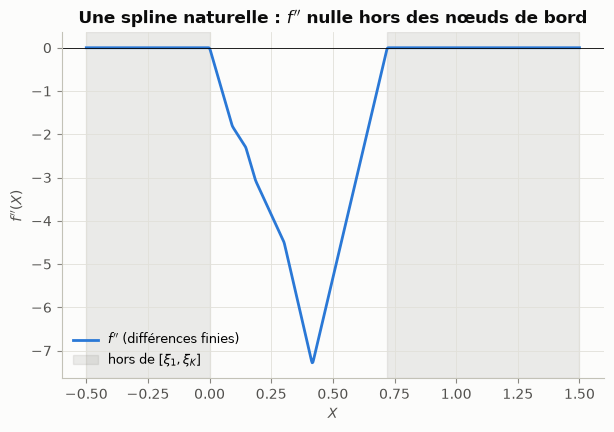

In [10]:
f2 = np.gradient(np.gradient(f_nat, x), x)
plt.figure(figsize=(7, 4.5))
plt.plot(x, f2, color=BLUE, label="$f''$ (différences finies)")
plt.axvspan(-0.5, xi[0], color=GRAY, alpha=0.15, label="hors de $[\\xi_1, \\xi_K]$")
plt.axvspan(xi[-1], 1.5, color=GRAY, alpha=0.15)
plt.axhline(0, color="k", lw=0.6)
plt.xlabel("$X$")
plt.ylabel("$f''(X)$")
plt.title("Une spline naturelle : $f''$ nulle hors des nœuds de bord")
plt.legend()
plt.show()

> **À retenir.** Linéarité aux deux bords = 4 contraintes linéaires
> $\beta_2 = \beta_3 = \sum\theta_k = \sum\xi_k\theta_k = 0$ ; en les éliminant, on
> obtient la base (5.4)-(5.5) de dimension $K$.

## Exercice 5.5 : Phonèmes : QDA sur des entrées filtrées par splines naturelles

**Énoncé.** Classer les données de phonèmes (5 classes) par analyse discriminante
quadratique (QDA, §4.3), après avoir filtré les 256 entrées corrélées par une base lisse de
splines cubiques naturelles (§5.2.3). Fixer à l'avance cinq choix du nombre et de la
position des nœuds, et sélectionner le meilleur par validation croisée à 10 plis.

**Rappels.**

- **QDA.** Chaque classe $k$ a une loi gaussienne $\mathcal N(\mu_k, \Sigma_k)$ et une
  probabilité a priori $\pi_k$. La règle de Bayes attribue $x$ à la classe maximisant
  $\delta_k(x) = -\frac12\log|\Sigma_k| - \frac12(x - \mu_k)^T\Sigma_k^{-1}(x - \mu_k) +
  \log\pi_k$ (éq. (4.12) du livre), avec $\mu_k, \Sigma_k, \pi_k$ estimés par leurs
  versions empiriques. En dimension 256, chaque $\Sigma_k$ a $256 \times 257/2 \approx
  33\,000$ paramètres : la variance est énorme.
- **Filtrage.** $x^* = \mathbf H^Tx$ où $\mathbf H$ ($256 \times M$) évalue $M$ splines
  naturelles aux fréquences. Remarquons que la QDA est **invariante par changement de
  base** ($x^* \mapsto \mathbf Ax^*$, $\mathbf A$ inversible change $\delta_k$ d'une même
  constante pour toutes les classes) : seul compte l'espace engendré par les colonnes de
  $\mathbf H$, c'est-à-dire le choix des nœuds.

In [11]:
ph = datasets.load_phoneme()
Xp = ph.filter(like="x.").to_numpy()
classes = np.unique(ph["g"])
yp = np.searchsorted(classes, ph["g"].to_numpy())
locuteur = ph["speaker"].to_numpy()
app = np.char.startswith(locuteur.astype(str), "train")
print("classes :", list(classes), "| apprentissage :", app.sum(), "| test :", (~app).sum())

classes : ['aa', 'ao', 'dcl', 'iy', 'sh'] | apprentissage : 3340 | test : 1169


In [12]:
def qda_fit(X, y, K):
    """Moyennes, covariances (facteur de Cholesky) et proportions de chaque classe."""
    modele = []
    for k in range(K):
        Xk = X[y == k]
        modele.append((Xk.mean(0), np.linalg.cholesky(np.cov(Xk.T)), len(Xk) / len(X)))
    return modele

def qda_predict(modele, X):
    scores = []
    for mu, L, pi in modele:
        Z = np.linalg.solve(L, (X - mu).T)          # ||Z||^2 = (x-mu)^T Sigma^-1 (x-mu)
        scores.append(-np.log(np.diag(L)).sum() - 0.5 * (Z ** 2).sum(0) + np.log(pi))
    return np.argmax(scores, axis=0)

**Cinq choix de nœuds fixés à l'avance** (fréquences ramenées à $[0, 1]$) : 5, 8, 12 et
20 nœuds équirépartis, et 12 nœuds concentrés vers les basses fréquences (positions
$u^2$ pour $u$ équiréparti), puisque le cours 1 a montré que l'information discriminante
y est concentrée.

In [ ]:
fs = np.arange(256) / 255
choix = {
    "5 nœuds uniformes": np.linspace(0, 1, 5),
    "8 nœuds uniformes": np.linspace(0, 1, 8),
    "12 nœuds uniformes": np.linspace(0, 1, 12),
    "12 nœuds basses fréq.": np.linspace(0, 1, 12) ** 2,
    "20 nœuds uniformes": np.linspace(0, 1, 20),
}